In [ ]:
import torch
from torch import nn
from torchvision import datasets
import matplotlib.pyplot as plt
from torchvision.transforms import ToTensor

In [9]:
train_data = datasets.FashionMNIST(
    root='data',
    train = True,
    download=True,
    transform=ToTensor(),
    target_transform= None
)

#load the test data
test_data = datasets.FashionMNIST(
    root = 'data',
    train = False,
    download=True,
    transform= ToTensor()
)

image, label = train_data[0]
image, label


(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

Image Shape: torch.Size([1, 28, 28])


Text(0.5, 1.0, '9')

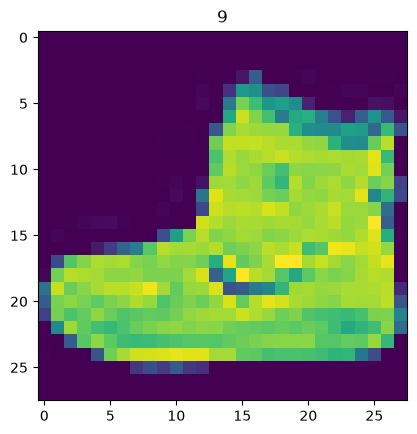

In [10]:
#visualise the data
image, label = train_data[0]
print(f"Image Shape: {image.shape}")
plt.imshow(image.squeeze())
plt.title(label)

In [11]:
from torch.utils.data import DataLoader 
BATCH_SIZE = 32

train_dataloader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_dataloader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"Dataloader: {train_dataloader, test_dataloader}")

print(f"Length of train dataloader: {len(train_dataloader)} batches of {BATCH_SIZE}")
print(f"Length of test dataloader: {len(test_dataloader)} batches of {BATCH_SIZE}")


Dataloader: (<torch.utils.data.dataloader.DataLoader object at 0x000002B37032FB60>, <torch.utils.data.dataloader.DataLoader object at 0x000002B3703374D0>)
Length of train dataloader: 1875 batches of 32
Length of test dataloader: 313 batches of 32


In [ ]:
#build a baseline model
class_names = train_data.classes

from torch import nn
class fashionmodel0(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_shape, hidden_units),
            nn.Linear(hidden_units, output_shape)
        )
    def forward(self, x):
        return self.layer_stack(x)

torch.manual_seed(42)
model0 = fashionmodel0(
    input_shape=784,
    hidden_units=10,
    output_shape=len(class_names)
)

model0

fashionmodel0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [18]:
from helper_functions import accuracy_fn
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    params = model0.parameters(),
    lr = 0.01
)

In [30]:
import torch

# Create a reusable training loop
def train_step(
    model: torch.nn.Module,
    data_loader: torch.utils.data.DataLoader,
    loss_fn: torch.nn.Module,
    optimizer: torch.optim.Optimizer,  # Fixed type hint from nn.Module to optim.Optimizer
    accuracy_fn
):
    train_loss, train_acc = 0, 0
    
    # Put the model in training mode
    model.train()

    for batch, (X, y) in enumerate(data_loader):
        # 1. Forward pass
        y_pred = model(X)

        # 2. Calculate loss
        loss = loss_fn(y_pred, y)
        train_loss += loss.item() # Use .item() to prevent tracking history across batches
        
        # 3. Calculate accuracy (Fixed: y_true=y, and applied argmax to logits if needed)
        train_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))

        # 4. Optimizer zero grad
        optimizer.zero_grad()

        # 5. Loss backward
        loss.backward()

        # 6. Optimizer step
        optimizer.step()

    # Scale loss and accuracy to get averages per batch
    train_loss /= len(data_loader)
    train_acc /= len(data_loader) # Fixed: Changed from test_acc to train_acc
    
    print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f}%")


def test_step(
    data_loader: torch.utils.data.DataLoader,
    model: torch.nn.Module,
    loss_fn: torch.nn.Module,
    accuracy_fn
):
    test_loss, test_acc = 0, 0

    # Put model in evaluation mode
    model.eval()
    
    # Turn on inference mode context manager
    with torch.inference_mode():
        for X, y in data_loader:
            # 1. Forward pass
            test_pred = model(X)

            # 2. Calculate loss and accuracy
            test_loss += loss_fn(test_pred, y).item() # Use .item() to save memory
            test_acc += accuracy_fn(y_true=y, y_pred=test_pred.argmax(dim=1))

        # Adjust metrics to get averages per batch
        test_loss /= len(data_loader)
        test_acc /= len(data_loader)
        
        print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%\n")


In [31]:
epochs = 3
for epoch in range(epochs):
    train_step(data_loader=train_dataloader,
               model = model0,
               loss_fn= loss_fn,
               optimizer=optimizer,
               accuracy_fn = accuracy_fn)

    test_step(data_loader = test_dataloader,
              model=model0,
              loss_fn=loss_fn,
              accuracy_fn=accuracy_fn)

Train loss: 0.47633 | Train accuracy: 83.52%
Test loss: 0.49816 | Test accuracy: 82.65%

Train loss: 0.46040 | Train accuracy: 84.09%
Test loss: 0.49034 | Test accuracy: 82.90%

Train loss: 0.44891 | Train accuracy: 84.38%
Test loss: 0.47597 | Test accuracy: 83.12%



In [32]:
#createa reusable function for model evaluations
def eval_model(
        model: torch.nn.Module,
        data_loader: torch.utils.data.dataloader,
        loss_fn: torch.nn.Module,
        accuracy_fn
):
    loss, acc = 0,0
    model.eval()

    with torch.inference_mode():
        for X, y in data_loader:
            y_pred = model(X)

            loss += loss_fn(y_pred, y)
            acc += accuracy_fn(y_true=y, y_pred = y_pred.argmax(dim =1))

        loss /= len(data_loader)
        acc /= len(data_loader)

    return {"model_name": model.__class__.__name__, # only works when model was created with a class
            "model_loss": loss.item(),
            "model_acc": acc}

In [34]:
first_model_results = eval_model(model=model0, data_loader=test_dataloader, loss_fn=loss_fn, accuracy_fn=accuracy_fn)
first_model_results

{'model_name': 'fashionmodel0',
 'model_loss': 0.4759677052497864,
 'model_acc': 83.11701277955271}